# BlueShift: NASA Data Download and Extraction

| Predictor | Product | Access |
|---|---|---|
| Chlorophyll-a | Aqua MODIS L3 CHL, 4 km | Earthdata Cloud |
| SST | Aqua MODIS L3 SST, 4 km | PO.DAAC Earthdata Cloud |

## 1. Import libraries and define paths

In [ ]:
from pathlib import Path
import tempfile

import earthaccess
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import regionmask
import xarray as xr

from shapely.geometry import box

D:\miniforge3\envs\blueshift\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:
BASE_DIR = Path("..")

# Existing coastal ocean zones
ZONES_FILE = BASE_DIR / "data/processed/ocean_zones/mindanao_coastal_ocean_zones.gpkg"

# Output folders
RAW_DIR = BASE_DIR / "data/raw/nasa"
PROCESSED_DIR = BASE_DIR / "data/processed/nasa"

CHL_DIR = PROCESSED_DIR / "chlorophyll_a"
SST_DIR = PROCESSED_DIR / "sst"

TEMP_DIR = BASE_DIR / "data/temp/nasa"

for folder in [CHL_DIR, SST_DIR, TEMP_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

## 2. Load and inspect coastal zones

In [ ]:
zones = gpd.read_file(ZONES_FILE)

if zones.crs is None:
    raise ValueError("Coastal zones have no CRS. Check the source file.")

zones = zones.to_crs("EPSG:4326")

print("Number of zones:", len(zones))
print("CRS:", zones.crs)
print("Columns:", zones.columns.tolist())
print("Geometry types:")
print(zones.geom_type.value_counts())

print("\nGeographic bounds:")
print(zones.total_bounds)

Number of zones: 24
CRS: EPSG:4326
Columns: ['province_id', 'province', 'geometry']
Geometry types:
MultiPolygon    24
Name: count, dtype: int64

Geographic bounds:
[117.92882769   4.451966   126.74023409  10.60682141]


## 3. Visualize the study area and bounding box

This is our first checkpoint. We'll plot the existing ocean zones and the rectangle that will be used for NASA searches.

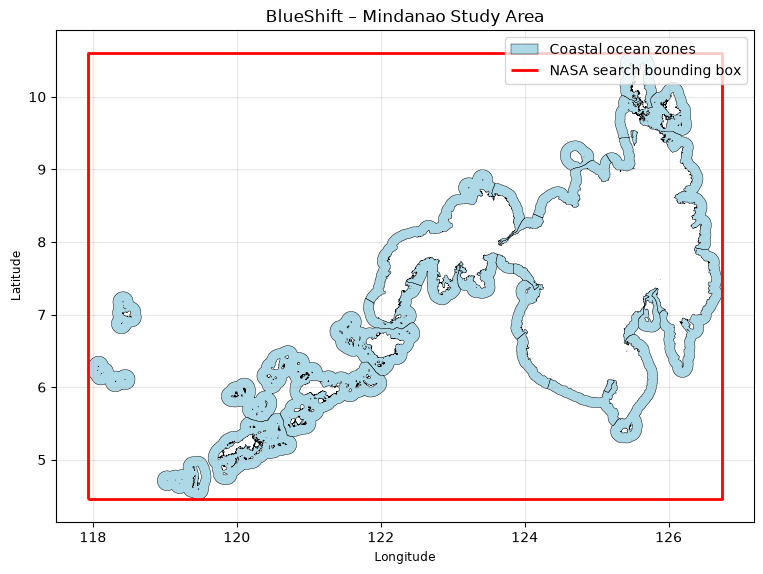

NASA bounding box: (np.float64(117.92882769491017), np.float64(4.4519660001785155), np.float64(126.74023409337413), np.float64(10.606821409170829))


In [ ]:
# Get geographic bounds
min_lon, min_lat, max_lon, max_lat = zones.total_bounds

BBOX = (min_lon, min_lat, max_lon, max_lat)

# Create bounding rectangle
bbox_gdf = gpd.GeoDataFrame(
    geometry=[box(min_lon, min_lat, max_lon, max_lat)],
    crs="EPSG:4326"
)

# Plot
fig, ax = plt.subplots(figsize=(9, 9))

zones.plot(
    ax=ax,
    color="lightblue",
    edgecolor="black",
    linewidth=0.3,
    label="Coastal ocean zones"
)

bbox_gdf.boundary.plot(
    ax=ax,
    color="red",
    linewidth=2,
    label="NASA search bounding box"
)

ax.set_title("BlueShift – Mindanao Study Area")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.legend()
ax.grid(alpha=0.3)

plt.show()

print("NASA bounding box:", BBOX)

Verify that:
- The zones cover the intended Mindanao coastal waters.
- The red rectangle encloses all the zones.
- The coordinates are in longitude and latitude, not projected meters.
    
If the map looks wrong, stop here. Don't download anything yet.

## 4. Authenticate with NASA

Register here: https://urs.earthdata.nasa.gov/users/new

In [ ]:
auth = earthaccess.login()

print("NASA Earthdata authentication successful.")

Enter your Earthdata Login username:  ianjure
Enter your Earthdata password:  ········


NASA Earthdata authentication successful.


You'll need your free NASA Earthdata account.

## 5. Define the NASA products

In [ ]:
PRODUCTS = {
    "chlorophyll_a": {
        "short_name": "MODISA_L3m_CHL",
        "variable": "chlor_a",
        "satellite": "AQUA_MODIS",
        "product_code": "CHL.chlor_a.4km",
        "output_dir": CHL_DIR
    },
    "sst": {
        "short_name": "MODIS_AQUA_L3_SST_THERMAL_MONTHLY_4KM_DAYTIME_V2019.0",
        "variable": "sst",
        "satellite": "AQUA_MODIS",
        "product_code": "SST.sst.4km",
        "output_dir": SST_DIR
    }
}

START_DATE = "2002-07"
END_DATE = "2026-05"

We'll use the same monthly period for both products.

## 6. Extract and filter coastal data

This function will:
- Crop the global raster to the Mindanao bounding box.
- Mask pixels outside the combined coastal zones.
- Filter chlorophyll-a using NASA's valid range.
- Filter SST using quality levels 0 and 1.
- Preserve the SST quality variable for later inspection.
- Save only the regional data.

In [ ]:
def extract_coastal_data(input_file, variable, output_file):

    with xr.open_dataset(input_file, engine="h5netcdf") as ds:

        # Find coordinates
        lat_name = "lat"
        lon_name = "lon"

        # Crop to study-area bounding box
        lat_idx = np.where(
            (ds[lat_name].values >= min_lat) &
            (ds[lat_name].values <= max_lat)
        )[0]

        lon_idx = np.where(
            (ds[lon_name].values >= min_lon) &
            (ds[lon_name].values <= max_lon)
        )[0]

        cropped = ds.isel(
            lat=lat_idx,
            lon=lon_idx
        )

        # Create combined coastal-zone geometry
        study_area = gpd.GeoDataFrame(
            geometry=[zones.geometry.union_all()],
            crs="EPSG:4326"
        )

        # Mask pixels outside coastal zones
        mask = regionmask.mask_geopandas(
            study_area,
            lon_or_obj=cropped[lon_name],
            lat=cropped[lat_name]
        )

        spatial_mask = mask.notnull()

        # Apply variable-specific filtering
        data = cropped[variable]

        if variable == "chlor_a":

            data = data.where(
                (data >= 0.001) &
                (data <= 100)
            )

        elif variable == "sst":

            quality = cropped["qual_sst"]

            data = data.where(
                quality.isin([0, 1])
            )

        data = data.where(spatial_mask)

        # Create output dataset
        output_ds = xr.Dataset({
            variable: data
        })

        if variable == "sst":

            output_ds["qual_sst"] = cropped["qual_sst"].where(
                spatial_mask
            )

        output_ds.attrs.update(ds.attrs)
        output_ds.attrs["study_area"] = "Mindanao coastal ocean zones"

        # Load cropped data before closing the remote file
        output_ds.load()

        # Save using a temporary file
        temp_file = output_file.with_name(
            output_file.stem + ".tmp.nc"
        )

        encoding = {
            name: {
                "zlib": True,
                "complevel": 4
            }
            for name in output_ds.data_vars
        }

        output_ds.to_netcdf(
            temp_file,
            encoding=encoding
        )

        temp_file.replace(output_file)

    return output_file

**Important:** The spatial mask uses the union of the zones, so it preserves the regional raster while excluding pixels outside the study area. We'll use the original individual zone polygons later when calculating statistics per zone.

## 7. Test extraction using July 2002

Before processing everything, let's download and extract just one month for both datasets.

In [ ]:
def search_monthly_granule(product, month):
    start = month.start_time
    end = month.end_time

    expected_filename = (
        f"{product['satellite']}."
        f"{start.strftime('%Y%m%d')}_"
        f"{end.strftime('%Y%m%d')}."
        f"L3m.MO.{product['product_code']}.nc"
    )

    results = earthaccess.search_data(
        short_name=product["short_name"],
        temporal=(
            start.strftime("%Y-%m-%d"),
            end.strftime("%Y-%m-%d")
        ),
        count=2000
    )

    for granule in results:
        for link in granule.data_links():
            if expected_filename in str(link):
                return granule

    return None

In [ ]:
test_month = pd.Period("2002-07", freq="M")

for name, product in PRODUCTS.items():

    print(f"\nProcessing {name}...")

    granule = search_monthly_granule(
        product,
        test_month
    )

    if granule is None:
        print("Granule not found.")
        continue

    remote_files = earthaccess.open([granule])

    try:
        output_file = (
            product["output_dir"] /
            f"{name}_200207.nc"
        )

        extract_coastal_data(
            remote_files[0],
            product["variable"],
            output_file
        )

        print(f"Saved: {output_file}")

    finally:
        for remote_file in remote_files:
            remote_file.close()


Processing chlorophyll_a...


QUEUEING TASKS | : 100%|██████████| 1/1 [00:00<00:00, 263.88it/s]
PROCESSING TASKS | : 100%|██████████| 1/1 [00:04<00:00,  4.78s/it]
COLLECTING RESULTS | : 100%|██████████| 1/1 [00:00<?, ?it/s]


Saved: ..\data\processed\nasa\chlorophyll_a\chlorophyll_a_200207.nc

Processing sst...


QUEUEING TASKS | : 100%|██████████| 1/1 [00:00<00:00, 316.86it/s]
PROCESSING TASKS | : 100%|██████████| 1/1 [00:04<00:00,  4.04s/it]
COLLECTING RESULTS | : 100%|██████████| 1/1 [00:00<00:00, 496.66it/s]


Saved: ..\data\processed\nasa\sst\sst_200207.nc


## 8. Visualize the extracted pixels

Let's verify that the actual NASA raster pixels overlap our coastal ocean zones.

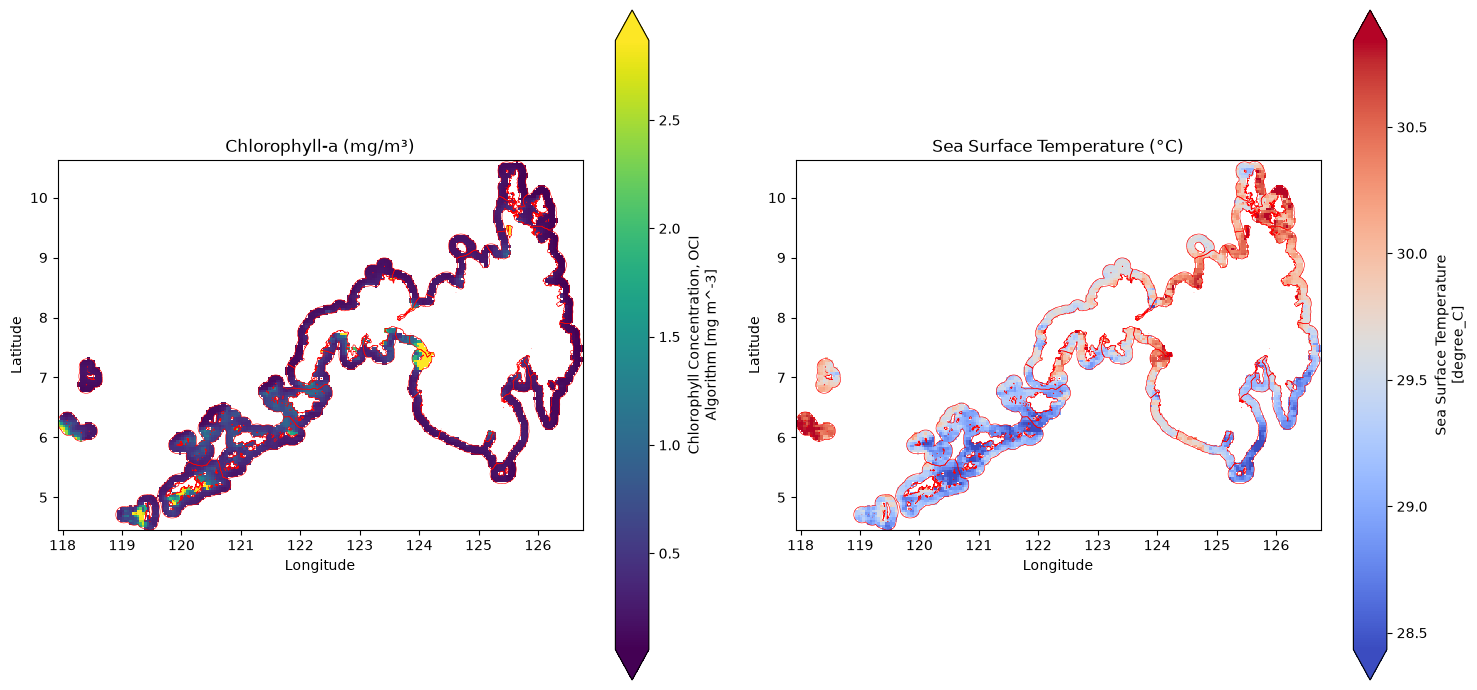

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 7))

datasets = [
    {
        "file": CHL_DIR / "chlorophyll_a_200207.nc",
        "variable": "chlor_a",
        "title": "Chlorophyll-a (mg/m³)",
        "cmap": "viridis"
    },
    {
        "file": SST_DIR / "sst_200207.nc",
        "variable": "sst",
        "title": "Sea Surface Temperature (°C)",
        "cmap": "coolwarm"
    }
]

for ax, item in zip(axes, datasets):

    with xr.open_dataset(item["file"]) as ds:

        ds[item["variable"]].plot(
            ax=ax,
            x="lon",
            y="lat",
            cmap=item["cmap"],
            robust=True
        )

        zones.boundary.plot(
            ax=ax,
            color="red",
            linewidth=0.4
        )

        ax.set_title(item["title"])
        ax.set_xlabel("Longitude")
        ax.set_ylabel("Latitude")

plt.tight_layout()
plt.show()

Check that:
- Raster pixels appear within the coastal ocean zones.
- Pixels outside the zones are masked.
- There are no unexpected gaps or spatial shifts.
- Both datasets cover the same study area.

Don't start the full processing until these plots look correct.

## 9. Download and process all months
Once both test extractions look correct, run the complete workflow.

We'll process one month at a time and use temporary directories so original global NetCDF files are automatically removed after processing.

In [ ]:
def process_product(name, product):

    print(f"\nProcessing {name}...")

    months = pd.period_range(
        START_DATE,
        END_DATE,
        freq="M"
    )

    missing = []
    failed = []
    processed = 0
    skipped = 0

    for month in months:

        output_file = (
            product["output_dir"] /
            f"{name}_{month.strftime('%Y%m')}.nc"
        )

        # Skip valid existing files
        if output_file.exists():

            try:
                with xr.open_dataset(output_file) as existing:
                    if product["variable"] in existing:
                        skipped += 1
                        continue
            except Exception:
                pass

        try:

            granule = search_monthly_granule(
                product,
                month
            )

            if granule is None:
                missing.append(str(month))
                print(f"Missing: {month}")
                continue

            remote_files = earthaccess.open([granule])

            try:
                extract_coastal_data(
                    remote_files[0],
                    product["variable"],
                    output_file
                )
            finally:
                for remote_file in remote_files:
                    remote_file.close()

            processed += 1
            print(f"Completed: {month}")

        except Exception as error:

            failed.append({
                "month": str(month),
                "error": str(error)
            })

            print(f"Failed: {month} - {error}")

    return {
        "processed": processed,
        "skipped": skipped,
        "missing": missing,
        "failed": failed
    }

Run both datasets:

In [ ]:
chl_results = process_product(
    "chlorophyll_a",
    PRODUCTS["chlorophyll_a"]
)

sst_results = process_product(
    "sst",
    PRODUCTS["sst"]
)


Processing chlorophyll_a...


QUEUEING TASKS | : 100%|██████████| 1/1 [00:00<00:00, 594.09it/s]
PROCESSING TASKS | : 100%|██████████| 1/1 [00:03<00:00,  3.91s/it]
COLLECTING RESULTS | : 100%|██████████| 1/1 [00:00<?, ?it/s]


Completed: 2002-10


QUEUEING TASKS | : 100%|██████████| 1/1 [00:00<?, ?it/s]
PROCESSING TASKS | : 100%|██████████| 1/1 [00:03<00:00,  3.56s/it]
COLLECTING RESULTS | : 100%|██████████| 1/1 [00:00<?, ?it/s]


Completed: 2002-11


QUEUEING TASKS | : 100%|██████████| 1/1 [00:00<00:00, 526.79it/s]
PROCESSING TASKS | : 100%|██████████| 1/1 [00:03<00:00,  3.33s/it]
COLLECTING RESULTS | : 100%|██████████| 1/1 [00:00<?, ?it/s]


... (1,129 outputs left out)

QUEUEING TASKS | : 100%|██████████| 1/1 [00:00<00:00, 131.32it/s]
PROCESSING TASKS | : 100%|██████████| 1/1 [00:03<00:00,  3.62s/it]
COLLECTING RESULTS | : 100%|██████████| 1/1 [00:00<?, ?it/s]


Completed: 2026-04


QUEUEING TASKS | : 100%|██████████| 1/1 [00:00<00:00, 396.36it/s]
PROCESSING TASKS | : 100%|██████████| 1/1 [00:03<00:00,  3.21s/it]
COLLECTING RESULTS | : 100%|██████████| 1/1 [00:00<?, ?it/s]


Completed: 2026-05


This will automatically skip the July 2002 test files and any other previously processed months.

## 10. Check download and processing results

In [ ]:
for name, results in [
    ("CHLOROPHYLL-A", chl_results),
    ("SEA SURFACE TEMPERATURE", sst_results)
]:

    print(f"\n{'=' * 40}")
    print(name)

    print("Newly processed:", results["processed"])
    print("Previously existing:", results["skipped"])
    print("Missing months:", len(results["missing"]))
    print("Failed months:", len(results["failed"]))

    if results["missing"]:
        print("Missing:", results["missing"])

    if results["failed"]:
        print("Errors:")
        for item in results["failed"]:
            print(item)


CHLOROPHYLL-A
Newly processed: 283
Previously existing: 3
Missing months: 1
Failed months: 0
Missing: ['2026-05']

SEA SURFACE TEMPERATURE
Newly processed: 286
Previously existing: 1
Missing months: 0
Failed months: 0
